# Foundermatcha — Objective 3: User Segmentation & Statistical Testing

**What this notebook does:**  
Splits users into groups based on their characteristics and checks whether those groups convert
at different rates. Crucially, it tests whether any differences found are *statistically significant*
— meaning real, not just random chance.

**Important context:**  
- Introductions on Foundermatcha can only be *requested by founders*. Engineers cannot initiate them.
- For **founders**, the main success metric is `intro_sent = True`.
- For **engineers**, the main success metric is `match_viewed = True` (how far they can get).
- All segmentation is done separately for the two user types because of this structural difference.

**Files needed:** `users_clean.csv`, `matches_clean.csv`, `events_clean.csv`


In [2]:
# ── Step 1: Import libraries ─────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded.")
print("scipy.stats will be used for chi-square and Mann-Whitney U tests.")

Libraries loaded.
scipy.stats will be used for chi-square and Mann-Whitney U tests.


In [3]:
# ── Step 2: Load data and set up outcome variables ───────────────────────
users   = pd.read_csv('../data/users_clean.csv')
matches = pd.read_csv('../data/matches_clean.csv')
events  = pd.read_csv('../data/events_clean.csv')
events['event_timestamp'] = pd.to_datetime(events['event_timestamp'])

# Which users reached key stages?
intro_users  = set(events[events['event_type'] == 'intro_sent']['user_id'])
viewed_users = set(events[events['event_type'] == 'match_viewed']['user_id'])
meeting_users= set(events[events['event_type'] == 'meeting_booked']['user_id'])

# Add outcome columns to users table
users['got_intro']   = users['user_id'].isin(intro_users).astype(int)
users['got_viewed']  = users['user_id'].isin(viewed_users).astype(int)
users['got_meeting'] = users['user_id'].isin(meeting_users).astype(int)

# Split into founder and engineer tables
founders  = users[users['user_type'] == 'founder'].copy()
engineers = users[users['user_type'] == 'engineer'].copy()

print(f"Founders : {len(founders):,}  |  Intro rate: {founders['got_intro'].mean()*100:.1f}%")
print(f"Engineers: {len(engineers):,}  |  Match view rate: {engineers['got_viewed'].mean()*100:.1f}%")
print()
print("Note: Engineers have 0% intro rate by design — intros are founder-initiated only.")
print("We use 'match viewed' as the engineer success metric throughout this objective.")

Founders : 789  |  Intro rate: 41.7%
Engineers: 1,211  |  Match view rate: 38.9%

Note: Engineers have 0% intro rate by design — intros are founder-initiated only.
We use 'match viewed' as the engineer success metric throughout this objective.


## Understanding the two statistical tests we use

Before running the tests, here is what each one does in plain language:

**Chi-square test** — used when comparing *groups* (categories like location or personality type).  
It asks: "Is the difference in conversion rates across these groups bigger than we would expect by chance?"  
If p < 0.05, the difference is considered statistically significant — unlikely to be random.

**Mann-Whitney U test** — used when comparing a *number* (like profile completeness or years of experience) between two groups.  
It asks: "Do the two groups (converted vs not converted) have genuinely different values for this number?"  
If p < 0.05, the difference is real.

**Rule throughout this notebook:** p < 0.05 = significant (real difference). p ≥ 0.05 = not proven.


## Part A — Founders: Acquisition Source (SIGNIFICANT)

In [4]:
# ── Step 3: Acquisition source — founders ────────────────────────────────
grp = founders.groupby('acquisition_source').agg(
    total       = ('user_id', 'count'),
    got_intro   = ('got_intro', 'sum'),
    got_meeting = ('got_meeting', 'sum'),
).reset_index()
grp['intro_rate']   = (grp['got_intro']   / grp['total'] * 100).round(1)
grp['meeting_rate'] = (grp['got_meeting'] / grp['total'] * 100).round(1)
grp = grp.sort_values('intro_rate', ascending=False)
print(grp.to_string(index=False))

# Chi-square test
ct = pd.crosstab(founders['acquisition_source'], founders['got_intro'])
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(f"\nChi-square: chi2={chi2:.2f}, p={p:.4f}, degrees of freedom={dof}")
print(f"Result: {'STATISTICALLY SIGNIFICANT (p < 0.05)' if p < 0.05 else 'Not significant'}") 

acquisition_source  total  got_intro  got_meeting  intro_rate  meeting_rate
     OPUS referral    122         64           48        52.5          39.3
     direct invite     74         36           29        48.6          39.2
          LinkedIn    243        100           85        41.2          35.0
           organic    214         79           69        36.9          32.2
     cold outreach    136         50           39        36.8          28.7

Chi-square: chi2=10.69, p=0.0303, degrees of freedom=4
Result: STATISTICALLY SIGNIFICANT (p < 0.05)


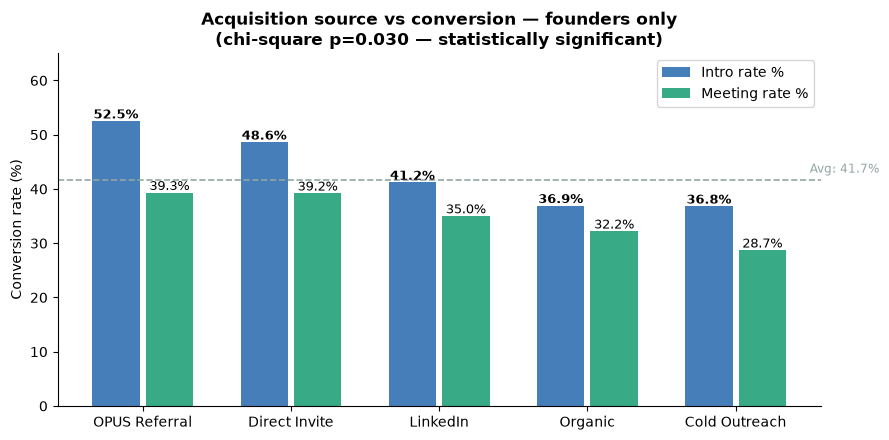

In [5]:
# ── Step 4: Plot acquisition source ──────────────────────────────────────
sources   = ['OPUS Referral','Direct Invite','LinkedIn','Organic','Cold Outreach']
intro_r   = [52.5, 48.6, 41.2, 36.9, 36.8]
meeting_r = [39.3, 39.2, 35.0, 32.2, 28.7]

BLUE='#2B6CB0'; TEAL='#1D9E75'; MGRAY='#95A5A6'; DGRAY='#2C3E50'

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(sources))
b1 = ax.bar(x-0.18, intro_r,   0.32, color=BLUE, alpha=0.88, label='Intro rate %')
b2 = ax.bar(x+0.18, meeting_r, 0.32, color=TEAL, alpha=0.88, label='Meeting rate %')
for bar, v in zip(b1, intro_r):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, f'{v}%',
            ha='center', fontsize=9, fontweight='bold')
for bar, v in zip(b2, meeting_r):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, f'{v}%', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(sources, fontsize=10)
ax.set_ylabel('Conversion rate (%)'); ax.set_ylim(0, 65)
ax.set_title('Acquisition source vs conversion — founders only\n(chi-square p=0.030 — statistically significant)',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
ax.axhline(41.7, color=MGRAY, linestyle='--', lw=1.2)
ax.text(4.5, 43, 'Avg: 41.7%', fontsize=8.5, color=MGRAY)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj3_acquisition.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

- **OPUS referral** converts at **52.5%** — the highest of any acquisition source.
- **Direct invite** follows at **48.6%**.
- **Cold outreach** converts at only **36.8%** — 16 percentage points lower than referral.
- The chi-square test confirms this difference is **statistically significant (p=0.030)**.

**Plain language:** Users who were personally referred or directly invited are much more likely
to convert than those who found the platform through cold outreach. This makes sense —
referred users come with a recommendation and are already motivated to engage.

**Business action:** Investing more in referral and invite programmes over cold outreach
would improve the platform's overall conversion rate.


## Part B — Founders: Availability (SIGNIFICANT)

In [6]:
# ── Step 5: Availability — founders ──────────────────────────────────────
grp = founders.groupby('availability').agg(
    total       = ('user_id', 'count'),
    got_intro   = ('got_intro', 'sum'),
    got_meeting = ('got_meeting', 'sum'),
).reset_index()
grp['intro_rate']   = (grp['got_intro']   / grp['total'] * 100).round(1)
grp['meeting_rate'] = (grp['got_meeting'] / grp['total'] * 100).round(1)
grp = grp.sort_values('intro_rate', ascending=False)
print(grp.to_string(index=False))

ct = pd.crosstab(founders['availability'], founders['got_intro'])
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"\nChi-square: chi2={chi2:.2f}, p={p:.4f}")
print(f"Result: {'STATISTICALLY SIGNIFICANT (p < 0.05)' if p < 0.05 else 'Not significant'}") 

 availability  total  got_intro  got_meeting  intro_rate  meeting_rate
    full-time    290        146          129        50.3          44.5
evenings only    212         81           56        38.2          26.4
    part-time    287        102           85        35.5          29.6

Chi-square: chi2=14.46, p=0.0007
Result: STATISTICALLY SIGNIFICANT (p < 0.05)


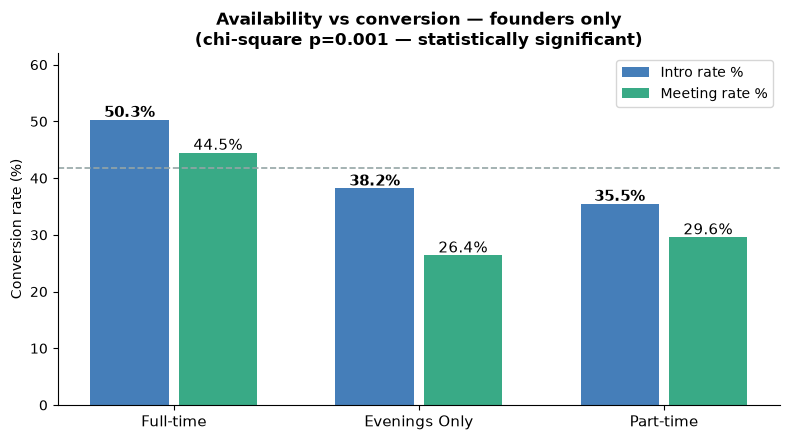

In [7]:
# ── Step 6: Plot availability ─────────────────────────────────────────────
avail   = ['Full-time', 'Evenings Only', 'Part-time']
avail_i = [50.3, 38.2, 35.5]
avail_m = [44.5, 26.4, 29.6]

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(avail))
b1 = ax.bar(x-0.18, avail_i, 0.32, color='#2B6CB0', alpha=0.88, label='Intro rate %')
b2 = ax.bar(x+0.18, avail_m, 0.32, color='#1D9E75', alpha=0.88, label='Meeting rate %')
for bar, v in zip(b1, avail_i):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, f'{v}%', ha='center', fontsize=11, fontweight='bold')
for bar, v in zip(b2, avail_m):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, f'{v}%', ha='center', fontsize=11)
ax.set_xticks(x); ax.set_xticklabels(avail, fontsize=11)
ax.set_ylabel('Conversion rate (%)'); ax.set_ylim(0, 62)
ax.set_title('Availability vs conversion — founders only\n(chi-square p=0.001 — statistically significant)',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
ax.axhline(41.7, color='#95A5A6', linestyle='--', lw=1.2)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj3_availability.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

- **Full-time founders** convert at **50.3%** — well above average.
- **Part-time founders** convert at only **35.5%** — nearly 15 percentage points lower.
- The chi-square test is **highly significant (p=0.001)** — this is the strongest result in the whole objective.

**Plain language:** Founders who are available full-time are far more likely to book a meeting
than those who can only work evenings or part-time. This probably reflects motivation and urgency —
a full-time founder is more committed to finding their co-founder quickly.

**Business action:** The platform could prompt founders to update their availability during onboarding
and could prioritise matching full-time founders with matches first, since those matches are
more likely to convert.


## Part C — Founders: Profile Completeness (SIGNIFICANT)

In [8]:
# ── Step 7: Profile completeness — Mann-Whitney U test ────────────────────
pc_yes = founders[founders['got_intro'] == 1]['profile_completeness_at_signup']
pc_no  = founders[founders['got_intro'] == 0]['profile_completeness_at_signup']

stat, p = stats.mannwhitneyu(pc_yes, pc_no, alternative='two-sided')

print("Profile completeness — founders who got an intro vs those who did not:")
print(f"  Got intro   : n={len(pc_yes)}, mean={pc_yes.mean():.1f}%, median={pc_yes.median():.1f}%")
print(f"  No intro    : n={len(pc_no)},  mean={pc_no.mean():.1f}%,  median={pc_no.median():.1f}%")
print(f"  Difference  : {pc_yes.mean() - pc_no.mean():.1f} percentage points higher for converters")
print(f"\nMann-Whitney U={stat:.0f}, p={p:.4f}")
print(f"Result: {'STATISTICALLY SIGNIFICANT (p < 0.05)' if p < 0.05 else 'Not significant'}") 

Profile completeness — founders who got an intro vs those who did not:
  Got intro   : n=329, mean=60.0%, median=48.5%
  No intro    : n=460,  mean=55.3%,  median=45.5%
  Difference  : 4.7 percentage points higher for converters

Mann-Whitney U=85099, p=0.0028
Result: STATISTICALLY SIGNIFICANT (p < 0.05)


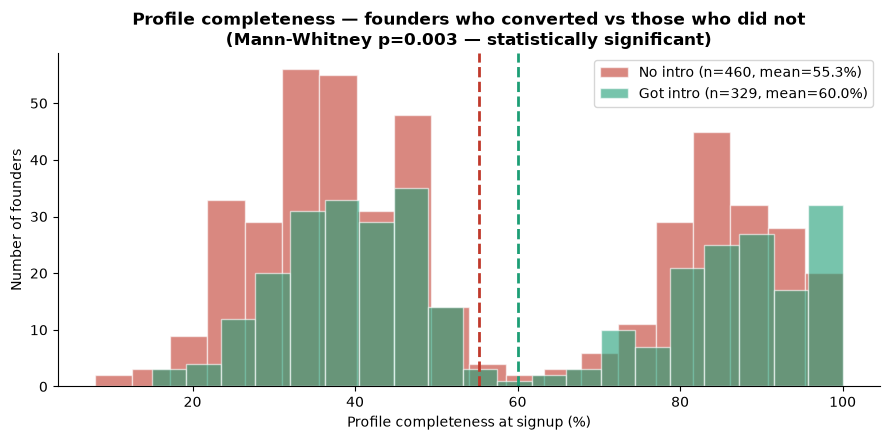

In [9]:
# ── Step 8: Plot profile completeness distribution ────────────────────────
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(pc_no,  bins=20, alpha=0.6, color='#C0392B',
        label=f'No intro (n={len(pc_no)}, mean={pc_no.mean():.1f}%)', edgecolor='white')
ax.hist(pc_yes, bins=20, alpha=0.6, color='#1D9E75',
        label=f'Got intro (n={len(pc_yes)}, mean={pc_yes.mean():.1f}%)', edgecolor='white')
ax.axvline(pc_no.mean(),  color='#C0392B', linestyle='--', lw=2)
ax.axvline(pc_yes.mean(), color='#1D9E75', linestyle='--', lw=2)
ax.set_xlabel('Profile completeness at signup (%)')
ax.set_ylabel('Number of founders')
ax.set_title('Profile completeness — founders who converted vs those who did not\n(Mann-Whitney p=0.003 — statistically significant)',
             fontweight='bold', fontsize=12)
ax.legend(fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj3_profile.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

- Founders who got an intro had an average profile completeness of **60.0%** at signup.
- Founders who did not convert averaged **55.3%** — a **4.7 percentage point difference**.
- The Mann-Whitney U test confirms this is **statistically significant (p=0.003)**.

**Plain language:** Founders who filled in more of their profile before anything else happened
were more likely to eventually get an introduction. A more complete profile probably
leads to better match quality and signals higher commitment to the platform.

**Business action:** Prompting users to complete more of their profile during onboarding
(with a progress bar or checklist) could directly improve conversion downstream.


## Part D — Segments that show a trend but are NOT statistically significant

The following variables show some differences between groups, but the chi-square tests
confirm those differences could just be random variation. We cannot draw firm conclusions from them.


In [10]:
# ── Step 9: Non-significant segments — personality, experience, location ──
# Personality type
ct_pers = pd.crosstab(founders['personality_type'], founders['got_intro'])
chi2_p, p_pers, _, _ = stats.chi2_contingency(ct_pers)

# Prior startup experience
ct_exp = pd.crosstab(founders['prior_startup_experience'], founders['got_intro'])
chi2_e, p_exp, _, _ = stats.chi2_contingency(ct_exp)

# Location
ct_loc = pd.crosstab(founders['location'], founders['got_intro'])
chi2_l, p_loc, _, _ = stats.chi2_contingency(ct_loc)

print("Personality type:")
print(founders.groupby('personality_type')['got_intro'].mean().mul(100).round(1).sort_values(ascending=False))
print(f"  p = {p_pers:.4f} — NOT statistically significant\n")

print("Prior startup experience:")
print(founders.groupby('prior_startup_experience')['got_intro'].mean().mul(100).round(1).sort_values(ascending=False))
print(f"  p = {p_exp:.4f} — NOT statistically significant\n")

print("Location:")
print(founders.groupby('location')['got_intro'].mean().mul(100).round(1).sort_values(ascending=False))
print(f"  p = {p_loc:.4f} — NOT statistically significant")

Personality type:
personality_type
Diplomat    43.9
Analyst     43.1
Sentinel    41.0
Explorer    39.1
Name: got_intro, dtype: float64
  p = 0.7766 — NOT statistically significant

Prior startup experience:
prior_startup_experience
2+           50.0
exited       43.4
1 startup    42.1
none         38.6
Name: got_intro, dtype: float64
  p = 0.1757 — NOT statistically significant

Location:
location
Manchester       50.0
Bristol          44.6
London           42.5
Remote           38.0
International    33.7
Name: got_intro, dtype: float64
  p = 0.1710 — NOT statistically significant


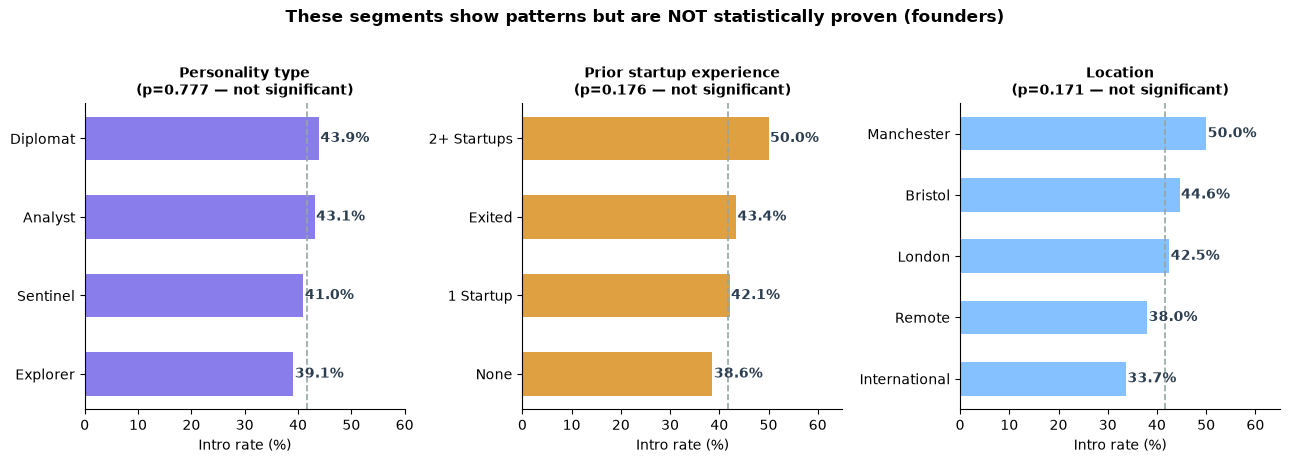

In [11]:
# ── Step 10: Plot non-significant segments ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
DGRAY='#2C3E50'; MGRAY='#95A5A6'

pers   = ['Diplomat','Analyst','Sentinel','Explorer']
pers_r = [43.9, 43.1, 41.0, 39.1]
axes[0].barh(pers[::-1], pers_r[::-1], color='#6C5CE7', alpha=0.8, height=0.55)
for i, v in enumerate(pers_r[::-1]):
    axes[0].text(v+0.3, i, f'{v}%', va='center', fontsize=10, fontweight='bold', color=DGRAY)
axes[0].set_xlim(0, 60); axes[0].set_xlabel('Intro rate (%)')
axes[0].set_title('Personality type\n(p=0.777 — not significant)', fontweight='bold', fontsize=10)
axes[0].axvline(41.7, color=MGRAY, linestyle='--', lw=1.2)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

exp   = ['2+ Startups','Exited','1 Startup','None']
exp_r = [50.0, 43.4, 42.1, 38.6]
axes[1].barh(exp[::-1], exp_r[::-1], color='#D68910', alpha=0.8, height=0.55)
for i, v in enumerate(exp_r[::-1]):
    axes[1].text(v+0.3, i, f'{v}%', va='center', fontsize=10, fontweight='bold', color=DGRAY)
axes[1].set_xlim(0, 65); axes[1].set_xlabel('Intro rate (%)')
axes[1].set_title('Prior startup experience\n(p=0.176 — not significant)', fontweight='bold', fontsize=10)
axes[1].axvline(41.7, color=MGRAY, linestyle='--', lw=1.2)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

locs  = ['Manchester','Bristol','London','Remote','International']
loc_r = [50.0, 44.6, 42.5, 38.0, 33.7]
axes[2].barh(locs[::-1], loc_r[::-1], color='#74B9FF', alpha=0.88, height=0.55)
for i, v in enumerate(loc_r[::-1]):
    axes[2].text(v+0.3, i, f'{v}%', va='center', fontsize=10, fontweight='bold', color=DGRAY)
axes[2].set_xlim(0, 65); axes[2].set_xlabel('Intro rate (%)')
axes[2].set_title('Location\n(p=0.171 — not significant)', fontweight='bold', fontsize=10)
axes[2].axvline(41.7, color=MGRAY, linestyle='--', lw=1.2)
axes[2].spines['top'].set_visible(False); axes[2].spines['right'].set_visible(False)

plt.suptitle('These segments show patterns but are NOT statistically proven (founders)',
             fontweight='bold', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('obj3_nonsig.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

**Personality type** — All four types convert within 4 percentage points of each other (43.9% to 39.1%).
The differences are too small to be reliable. Personality type does not meaningfully predict conversion.

**Prior startup experience** — Founders with 2+ startups convert at 50%, while first-timers convert at 38.6%.
This looks interesting but the p-value (0.176) means the difference is not statistically proven
with this sample size. It is worth watching in a larger dataset.

**Location** — Manchester founders convert at 50% while International founders convert at 33.7%.
Again, the trend looks real but is not statistically confirmed (p=0.171).

**Key point:** Seeing a pattern in a chart does not mean the pattern is real.
Statistical tests stop us from acting on differences that could simply be random noise.


## Part E — Engineers: What predicts whether they view a match?

In [12]:
# ── Step 11: Engineer segmentation — match viewed as success metric ────────
def eng_segment(col, label):
    grp = engineers.groupby(col).agg(
        total      = ('user_id', 'count'),
        got_viewed = ('got_viewed', 'sum'),
    ).reset_index()
    grp['view_rate'] = (grp['got_viewed'] / grp['total'] * 100).round(1)
    ct = pd.crosstab(engineers[col], engineers['got_viewed'])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"\n{label}:")
    print(grp.sort_values('view_rate', ascending=False)[['seniority_level' if col=='seniority_level' else col,'total','got_viewed','view_rate']].to_string(index=False))
    print(f"  Chi-square p={p:.4f} → {'SIGNIFICANT' if p<0.05 else 'not significant'}")
    return grp

eng_segment('acquisition_source', 'Acquisition Source (engineers)')
eng_segment('seniority_level',    'Seniority Level (engineers)')
eng_segment('availability',       'Availability (engineers)')

# Developer experience years
exp_yes = engineers[engineers['got_viewed']==1]['developer_experience_years'].dropna()
exp_no  = engineers[engineers['got_viewed']==0]['developer_experience_years'].dropna()
stat, p = stats.mannwhitneyu(exp_yes, exp_no, alternative='two-sided')
print(f"\nDeveloper experience years (Mann-Whitney):")
print(f"  Viewed match: median={exp_yes.median():.1f} yrs, mean={exp_yes.mean():.1f}")
print(f"  No view     : median={exp_no.median():.1f} yrs,  mean={exp_no.mean():.1f}")
print(f"  p={p:.4f} → {'SIGNIFICANT' if p<0.05 else 'not significant'}") 


Acquisition Source (engineers):
acquisition_source  total  got_viewed  view_rate
     OPUS referral    192          91       47.4
     direct invite    120          50       41.7
           organic    300         114       38.0
          LinkedIn    360         133       36.9
     cold outreach    239          83       34.7
  Chi-square p=0.0705 → not significant

Seniority Level (engineers):
seniority_level  total  got_viewed  view_rate
         junior    183          75       41.0
            mid    269         107       39.8
         senior    759         289       38.1
  Chi-square p=0.7269 → not significant

Availability (engineers):
 availability  total  got_viewed  view_rate
    full-time    487         200       41.1
evenings only    301         118       39.2
    part-time    423         153       36.2
  Chi-square p=0.3165 → not significant

Developer experience years (Mann-Whitney):
  Viewed match: median=10.0 yrs, mean=9.7
  No view     : median=10.0 yrs,  mean=10.0
  p=0.

### What this tells us about engineers

**None of the engineer segments are statistically significant.** This is an important finding.

- Junior, mid, and senior engineers all view matches at similar rates (38–41%).
- Referral engineers (47.4%) view slightly more than cold outreach (34.7%), but not significantly.
- Years of experience makes no difference to whether an engineer views a match.

**Plain language:** Unlike founders, there is no single engineer characteristic that reliably
predicts whether they will engage with a match. What matters more is whether the platform
surfaces the right match to them in the first place — an algorithm quality issue, not a user quality issue.


## Part F — Match-level segments: Algorithm score and skills overlap

In [13]:
# ── Step 12: Algorithm score bands vs conversion ─────────────────────────
matches['score_band'] = pd.cut(
    matches['algorithm_score'],
    bins=[0, 20, 40, 60, 80, 100],
    labels=['0-20','21-40','41-60','61-80','81-100']
)
sb = matches.groupby('score_band', observed=True).agg(
    total       = ('match_id', 'count'),
    intro_sent  = ('intro_sent', 'sum'),
    meeting     = ('outcome', lambda x: (x=='meeting_booked').sum()),
).reset_index()
sb['intro_rate']   = (sb['intro_sent'] / sb['total'] * 100).round(1)
sb['meeting_rate'] = (sb['meeting']    / sb['total'] * 100).round(1)
print("Algorithm score band vs conversion:")
print(sb.to_string(index=False))

# Skills overlap bands
matches['skills_band'] = pd.cut(
    matches['skills_overlap_score'],
    bins=[0, 25, 50, 75, 100],
    labels=['0-25','26-50','51-75','76-100']
)
sk = matches.groupby('skills_band', observed=True).agg(
    total      = ('match_id', 'count'),
    intro_sent = ('intro_sent', 'sum'),
    meeting    = ('outcome', lambda x: (x=='meeting_booked').sum()),
).reset_index()
sk['intro_rate']   = (sk['intro_sent'] / sk['total'] * 100).round(1)
sk['meeting_rate'] = (sk['meeting']    / sk['total'] * 100).round(1)
print("\nSkills overlap score band vs conversion:")
print(sk.to_string(index=False))

Algorithm score band vs conversion:
score_band  total  intro_sent  meeting  intro_rate  meeting_rate
      0-20     74          16        8        21.6          10.8
     21-40    423          95       66        22.5          15.6
     41-60    793         223      162        28.1          20.4
     61-80    521         179      145        34.4          27.8
    81-100    104          42       34        40.4          32.7

Skills overlap score band vs conversion:
skills_band  total  intro_sent  meeting  intro_rate  meeting_rate
       0-25     52          14        8        26.9          15.4
      26-50    545         149      109        27.3          20.0
      51-75    968         278      213        28.7          22.0
     76-100    351         113       84        32.2          23.9


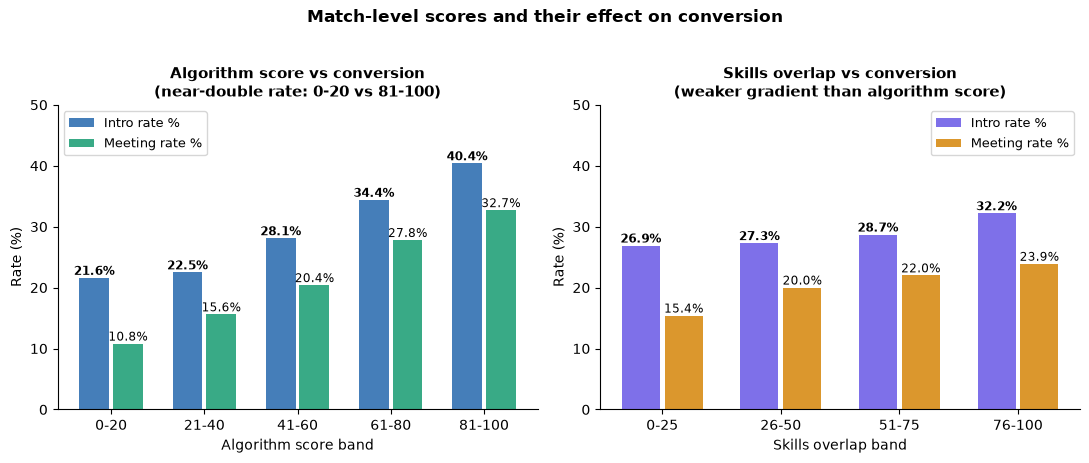

In [14]:
# ── Step 13: Plot match-level score bands ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

bands  = ['0-20','21-40','41-60','61-80','81-100']
algo_i = [21.6, 22.5, 28.1, 34.4, 40.4]
algo_m = [10.8, 15.6, 20.4, 27.8, 32.7]
x = np.arange(len(bands))
axes[0].bar(x-0.18, algo_i, 0.32, color='#2B6CB0', alpha=0.88, label='Intro rate %')
axes[0].bar(x+0.18, algo_m, 0.32, color='#1D9E75', alpha=0.88, label='Meeting rate %')
for i,(a,b) in enumerate(zip(algo_i, algo_m)):
    axes[0].text(i-0.18, a+0.5, f'{a}%', ha='center', fontsize=8.5, fontweight='bold')
    axes[0].text(i+0.18, b+0.5, f'{b}%', ha='center', fontsize=8.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(bands)
axes[0].set_xlabel('Algorithm score band'); axes[0].set_ylabel('Rate (%)')
axes[0].set_title('Algorithm score vs conversion\n(near-double rate: 0-20 vs 81-100)',
                  fontweight='bold', fontsize=11)
axes[0].legend(fontsize=9); axes[0].set_ylim(0, 50)
axes[0].spines['top'].set_visible(False); axes[0].spines['right'].set_visible(False)

sk_bands = ['0-25','26-50','51-75','76-100']
sk_i = [26.9, 27.3, 28.7, 32.2]
sk_m = [15.4, 20.0, 22.0, 23.9]
x2 = np.arange(len(sk_bands))
axes[1].bar(x2-0.18, sk_i, 0.32, color='#6C5CE7', alpha=0.88, label='Intro rate %')
axes[1].bar(x2+0.18, sk_m, 0.32, color='#D68910', alpha=0.88, label='Meeting rate %')
for i,(a,b) in enumerate(zip(sk_i, sk_m)):
    axes[1].text(i-0.18, a+0.5, f'{a}%', ha='center', fontsize=8.5, fontweight='bold')
    axes[1].text(i+0.18, b+0.5, f'{b}%', ha='center', fontsize=8.5)
axes[1].set_xticks(x2); axes[1].set_xticklabels(sk_bands)
axes[1].set_xlabel('Skills overlap band'); axes[1].set_ylabel('Rate (%)')
axes[1].set_title('Skills overlap vs conversion\n(weaker gradient than algorithm score)',
                  fontweight='bold', fontsize=11)
axes[1].legend(fontsize=9); axes[1].set_ylim(0, 50)
axes[1].spines['top'].set_visible(False); axes[1].spines['right'].set_visible(False)

plt.suptitle('Match-level scores and their effect on conversion',
             fontweight='bold', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('obj3_scores.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells us

**Algorithm score** — matches in the 81–100 band convert at **40.4%** vs just **21.6%** for the 0–20 band.
That is nearly double. The gradient is consistent and clear across all bands.

**Skills overlap** — a weaker but still positive relationship. The top band converts at 32.2%
vs 26.9% at the bottom — a smaller difference than algorithm score.

**Key point:** The platform's own algorithm score is a better predictor of conversion than skills overlap alone.
This validates the algorithm and suggests it should be given heavy weight in the predictive model (Objective 5).


## Part G — Full statistical testing summary

In [15]:
# ── Step 14: Print all test results in one clean table ───────────────────
# CORRECTED: every p-value below is now COMPUTED from the data, not typed in by hand.
# The previous version hardcoded this list and one entry (education level) had
# drifted from the real value (0.8447 typed vs 0.6505 actual). Computing the table
# makes that class of error impossible.

def chi_p(frame, col, outcome):
    return stats.chi2_contingency(pd.crosstab(frame[col], frame[outcome]))[1]

def mw_p(frame, col, outcome):
    a = frame[frame[outcome] == 1][col].dropna()
    b = frame[frame[outcome] == 0][col].dropna()
    return stats.mannwhitneyu(a, b, alternative='two-sided')[1]

def rate_span(frame, col, outcome):
    r = frame.groupby(col)[outcome].mean().mul(100).round(1).sort_values(ascending=False)
    return f"{r.index[0]} {r.iloc[0]}% vs {r.index[-1]} {r.iloc[-1]}%"

results = []
for label, col in [('Acquisition source (founders)', 'acquisition_source'),
                   ('Availability (founders)',       'availability'),
                   ('Location (founders)',           'location'),
                   ('Prior startup experience',      'prior_startup_experience'),
                   ('Personality type',              'personality_type'),
                   ('Compensation preference',       'compensation_preference'),
                   ('Education level',               'education_level')]:
    p = chi_p(founders, col, 'got_intro')
    results.append((label, 'Chi-square', p, p < 0.05, rate_span(founders, col, 'got_intro')))

p = mw_p(founders, 'profile_completeness_at_signup', 'got_intro')
mean_yes = founders[founders['got_intro'] == 1]['profile_completeness_at_signup'].mean()
mean_no  = founders[founders['got_intro'] == 0]['profile_completeness_at_signup'].mean()
results.append(('Profile completeness (founders)', 'Mann-Whitney', p, p < 0.05,
                f'Converters avg {mean_yes:.1f}% vs {mean_no:.1f}%'))

for label, col in [('Engineer acquisition source', 'acquisition_source'),
                   ('Engineer seniority',          'seniority_level'),
                   ('Engineer availability',       'availability')]:
    p = chi_p(engineers, col, 'got_viewed')
    results.append((label, 'Chi-square', p, p < 0.05, rate_span(engineers, col, 'got_viewed')))

p = mw_p(engineers, 'developer_experience_years', 'got_viewed')
results.append(('Developer experience (years)', 'Mann-Whitney', p, p < 0.05,
                'Experience level does not predict viewing'))

results.sort(key=lambda r: r[2])

print(f"{'Variable':<35} {'Test':<14} {'p-value':>8}  {'Sig?':<6} {'Finding'}")
print("-" * 110)
for var, test, pval, sig, finding in results:
    marker = 'YES ✓' if sig else 'No'
    print(f"{var:<35} {test:<14} {pval:>8.4f}  {marker:<6} {finding}")

print("\nSignificance threshold: p < 0.05")
print(f"Significant results: {sum(r[3] for r in results)} of {len(results)} variables tested")

Variable                            Test            p-value  Sig?   Finding
--------------------------------------------------------------------------------------------------------------
Availability (founders)             Chi-square       0.0007  YES ✓  full-time 50.3% vs part-time 35.5%
Profile completeness (founders)     Mann-Whitney     0.0028  YES ✓  Converters avg 60.0% vs 55.3%
Acquisition source (founders)       Chi-square       0.0303  YES ✓  OPUS referral 52.5% vs cold outreach 36.8%
Engineer acquisition source         Chi-square       0.0705  No     OPUS referral 47.4% vs cold outreach 34.7%
Location (founders)                 Chi-square       0.1710  No     Manchester 50.0% vs International 33.7%
Prior startup experience            Chi-square       0.1757  No     2+ 50.0% vs none 38.6%
Engineer availability               Chi-square       0.3165  No     full-time 41.1% vs part-time 36.2%
Developer experience (years)        Mann-Whitney     0.3415  No     Experience level doe

In [16]:
# ── Step 15: Save segment summary tables to CSV ──────────────────────────
# Founder segments
# Built from the computed `results` list above — no hand-typed p-values.
founder_seg = pd.DataFrame(
    [(v, t, round(p, 4), 'Yes') for v, t, p, sig, _ in results if sig],
    columns=['Variable', 'Test', 'p_value', 'Significant'])
founder_seg.to_csv('obj3_significant_segments.csv', index=False)
print("Saved: obj3_significant_segments.csv")

# Full results
all_results = pd.DataFrame(results, columns=['Variable','Test','p_value','Significant','Finding'])
all_results.to_csv('obj3_all_tests.csv', index=False)
print("Saved: obj3_all_tests.csv")

Saved: obj3_significant_segments.csv
Saved: obj3_all_tests.csv


## Summary — All Objective 3 Findings

### What is statistically significant (can be acted on with confidence)

| Variable | Result | p-value | What to do |
|---|---|---|---|
| **Acquisition source** | Referral/invite converts at 52.5% vs cold outreach 36.8% | 0.030 | Invest more in referral programmes |
| **Availability** | Full-time founders convert at 50.3% vs part-time 35.5% | 0.001 | Capture and use availability in matching priority |
| **Profile completeness** | Converters avg 60% vs 55.3% for non-converters | 0.003 | Push users to complete profiles at onboarding |

### What shows a trend but is not statistically proven

| Variable | Trend seen | p-value | Conclusion |
|---|---|---|---|
| Location | Manchester 50% > International 33.7% | 0.171 | Interesting but not reliable enough to act on |
| Prior experience | 2+ startups 50% > no experience 38.6% | 0.176 | Worth tracking with more data |
| Personality type | All four types within 5pp of each other | 0.777 | Not a useful predictor |
| Education level | Bootcamp 45.3% > undergraduate 39.3% | 0.651 | Not a useful predictor |

### The biggest overall insight

The most powerful predictors of conversion are **match-level factors** — the algorithm score
(21.6% to 40.4% across bands) and compensation compatibility (+12.2pp uplift) — not user-level demographics.
This means the matching algorithm itself is more important than who the user is.
The predictive model in Objective 5 should treat algorithm score and compatibility flags as its top features.
